## Часть 1. EDA и Preprocessing.

1. Скачайте данные по клиентам немецкого банка: https://www.kaggle.com/uciml/german-credit;

2. Проведите EDA, чтобы познакомиться с признаками;

3. Преобразуйте все признаки в числовые подходящими методами;

4. Приведите все данные к одному масштабу (а заодно поясните, почему это необходимая операция при кластеризации).

In [739]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.simplefilter("ignore")

In [740]:
df = pd.read_csv('german_credit_data.csv')

In [741]:
df.head()

,Unnamed: 0,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose
0,0,67,male,2,own,NaN,little,1169,6,radio/TV
1,1,22,female,2,own,little,moderate,5951,48,radio/TV
2,2,49,male,1,own,little,NaN,2096,12,education
3,3,45,male,2,free,little,little,7882,42,furniture/equipment
4,4,53,male,2,free,little,little,4870,24,car


#### Описание полей:

Age (numeric)

Sex (text: male, female)

Job (numeric: 0 - unskilled and non-resident, 1 - unskilled and resident, 2 - skilled, 3 - highly skilled)

Housing (text: own, rent, or free)

Saving accounts (text - little, moderate, quite rich, rich)

Checking account (text - little, moderate, rich)

Credit amount (numeric, in DM)

Duration (numeric, in month)

Purpose (text: car, furniture/equipment, radio/TV, domestic appliances, repairs, education, business, vacation/others)

In [742]:
df = df[df.columns.drop(['Unnamed: 0'])]

In [743]:
df.describe()

,Age,Job,Credit amount,Duration
count,1000.000000,1000.000000,1000.000000,1000.000000
mean,35.546000,1.904000,3271.258000,20.903000
std,11.375469,0.653614,2822.736876,12.058814
min,19.000000,0.000000,250.000000,4.000000
25%,27.000000,2.000000,1365.500000,12.000000
50%,33.000000,2.000000,2319.500000,18.000000
75%,42.000000,2.000000,3972.250000,24.000000
max,75.000000,3.000000,18424.000000,72.000000


In [744]:
df.isnull().sum()

Age                   0
Sex                   0
Job                   0
Housing               0
Saving accounts     183
Checking account    394
Credit amount         0
Duration              0
Purpose               0
dtype: int64

In [745]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Age               1000 non-null   int64 
 1   Sex               1000 non-null   object
 2   Job               1000 non-null   int64 
 3   Housing           1000 non-null   object
 4   Saving accounts   817 non-null    object
 5   Checking account  606 non-null    object
 6   Credit amount     1000 non-null   int64 
 7   Duration          1000 non-null   int64 
 8   Purpose           1000 non-null   object
dtypes: int64(4), object(5)
memory usage: 70.4+ KB


In [746]:
df.nunique()

Age                  53
Sex                   2
Job                   4
Housing               3
Saving accounts       4
Checking account      3
Credit amount       921
Duration             33
Purpose               8
dtype: int64

In [747]:
df = df.fillna('Missing')
df.head()

,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose
0,67,male,2,own,Missing,little,1169,6,radio/TV
1,22,female,2,own,little,moderate,5951,48,radio/TV
2,49,male,1,own,little,Missing,2096,12,education
3,45,male,2,free,little,little,7882,42,furniture/equipment
4,53,male,2,free,little,little,4870,24,car


In [748]:
df_num = df.select_dtypes(include=['int64'])
df_num.head()

,Age,Job,Credit amount,Duration
0,67,2,1169,6
1,22,2,5951,48
2,49,1,2096,12
3,45,2,7882,42
4,53,2,4870,24


array([[<Axes: title={'center': 'Age'}>, <Axes: title={'center': 'Job'}>],
       [<Axes: title={'center': 'Credit amount'}>,
        <Axes: title={'center': 'Duration'}>]], dtype=object)

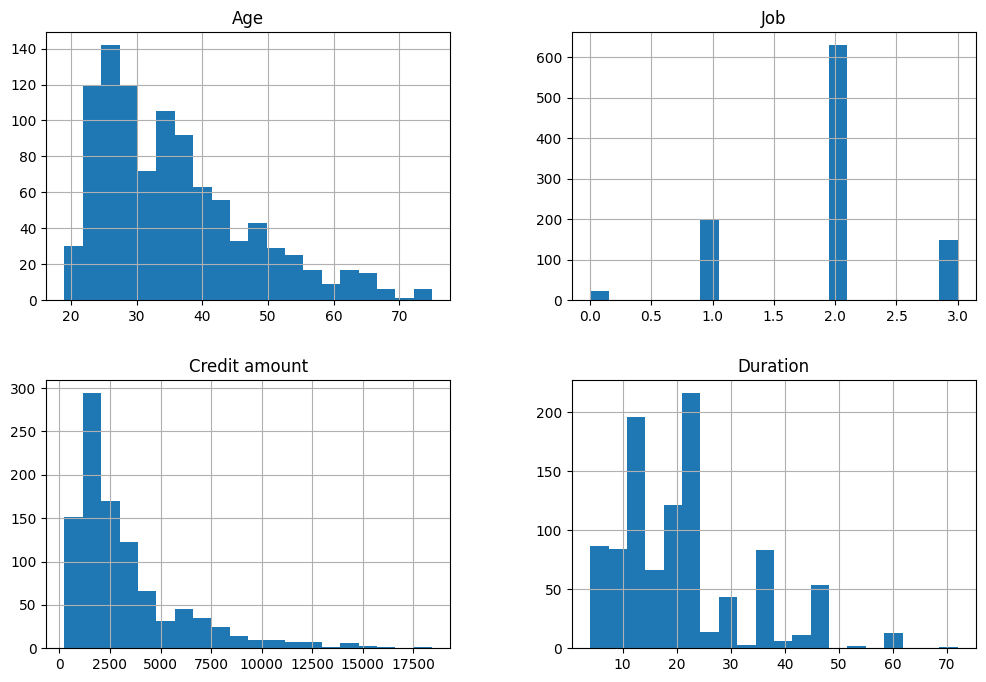

In [749]:
df_num.hist(figsize=(12, 8), bins=20)

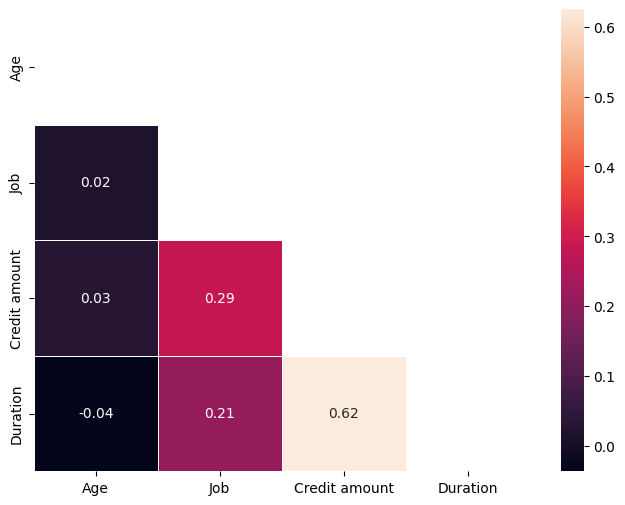

In [750]:
corr = df_num.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
plt.figure(figsize=(8, 6))
sns.heatmap(corr, mask = mask, annot=True, cbar=True, linewidths=.5, fmt= '.2f')
plt.show()

In [751]:
import math

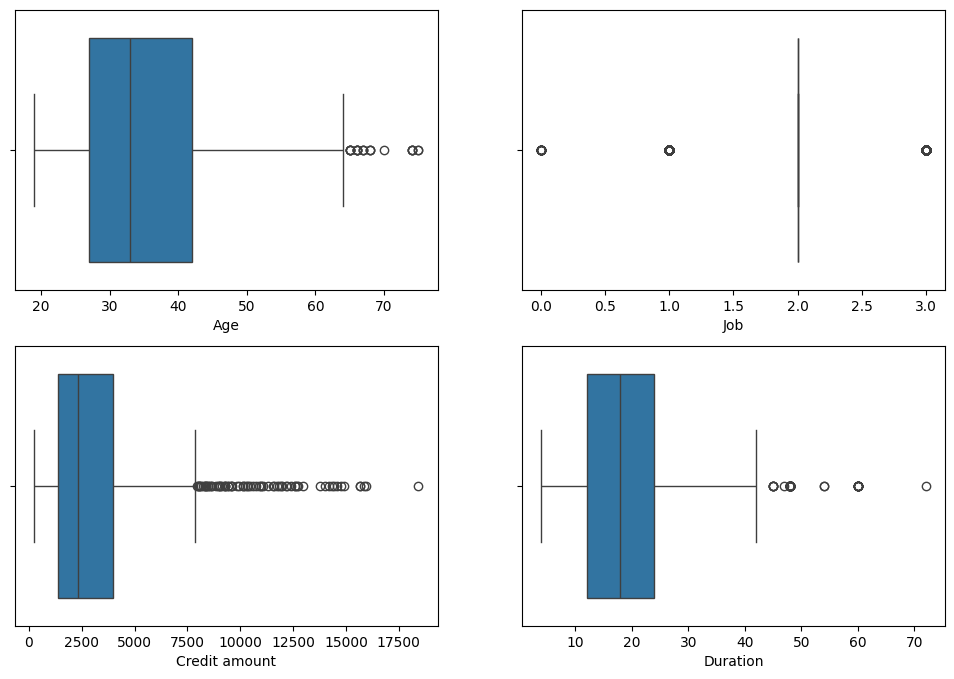

In [752]:
# Выводим графики в два столбца, используя subplots
ncols = 2
nrows = math.ceil(len(df_num.columns)/ncols)

figure, axis = plt.subplots( nrows, ncols,figsize=(12, 8))
for i, col in enumerate(df_num):
   sns.boxplot(ax=axis[i//ncols, i%ncols],x=df[col])

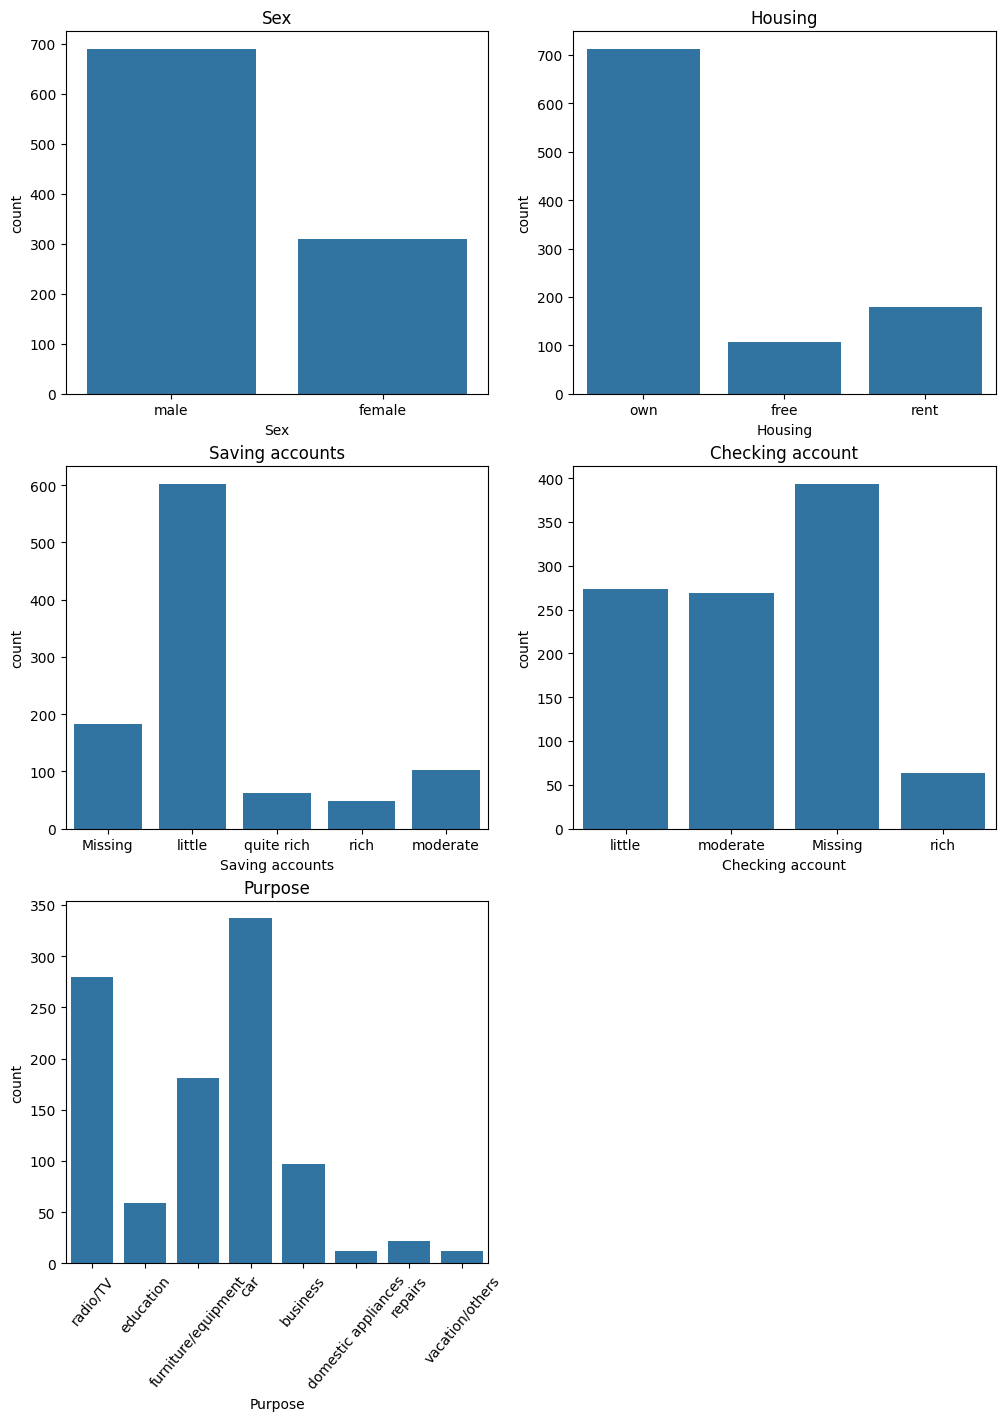

In [753]:
df_cat = df[df.select_dtypes(include=['object']).columns]

ncols = 2
nrows = math.ceil(len(df_cat.columns)/ncols)
figure, axis = plt.subplots( nrows, ncols,figsize=(12, 16))

for i, col in enumerate(df_cat):
   sns.countplot(ax=axis[i//ncols, i%ncols], data = df_cat, x=col)
   axis[i//ncols, i%ncols].set_title(col)

axis[2,0].tick_params(axis='x', labelrotation=50)
axis[2,1].remove()


In [755]:
df_trans= df.copy()

In [756]:
from sklearn.preprocessing import LabelEncoder

In [757]:
le = LabelEncoder()

In [758]:
# Кодируем данные в числовые, сохраняя порядок по возрастанию
#Saving accounts (text - little, moderate, quite rich, rich)
le.fit(['Missing', 'little', 'moderate', 'quite rich', 'rich'])
df_trans['Saving accounts'] = le.transform(df_trans['Saving accounts'])

In [759]:
#Checking account (text - little, moderate, rich)
le.fit(['Missing', 'little', 'moderate', 'rich'])
df_trans['Checking account'] = le.transform(df_trans['Checking account'])

In [760]:
for col in ['Sex', 'Housing', 'Purpose']:
    df_trans[col] = le.fit_transform(df_trans[col])

df_trans

,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose
0,67,1,2,1,0,1,1169,6,5
1,22,0,2,1,1,2,5951,48,5
2,49,1,1,1,1,0,2096,12,3
3,45,1,2,0,1,1,7882,42,4
4,53,1,2,0,1,1,4870,24,1
...,...,...,...,...,...,...,...,...,...
995,31,0,1,1,1,0,1736,12,4
996,40,1,3,1,1,1,3857,30,1
997,38,1,2,1,1,0,804,12,5
998,23,1,2,0,1,1,1845,45,5


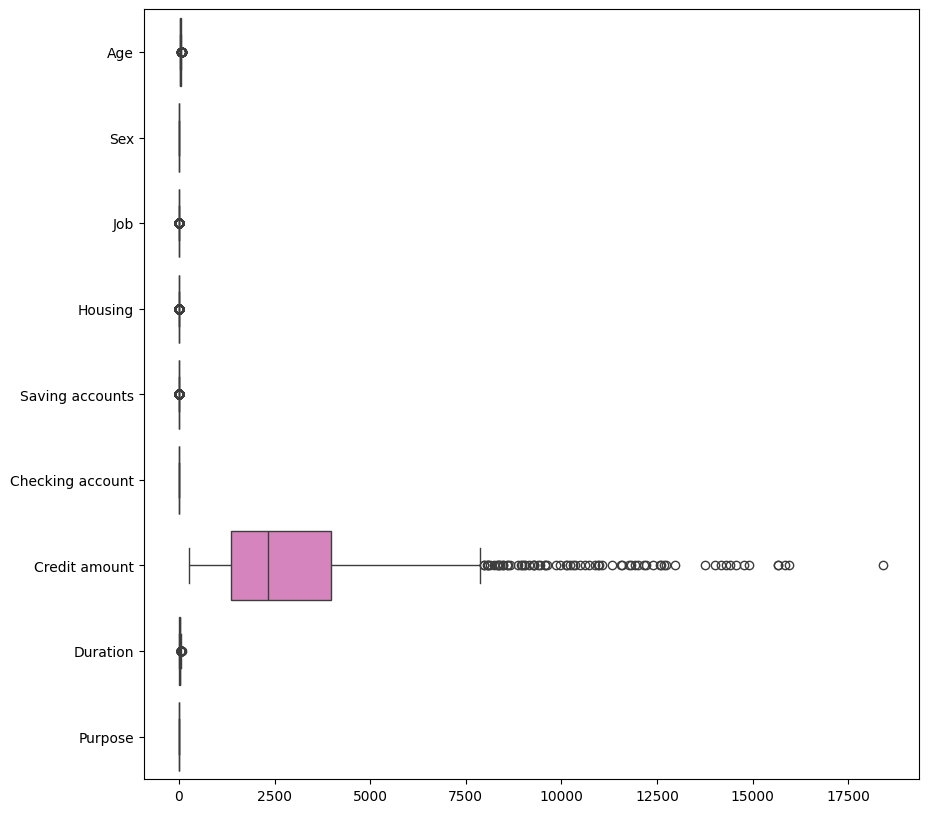

In [761]:
plt.figure(figsize=(10,10))
sns.boxplot(data=df_trans, orient='h');

In [762]:
from sklearn.preprocessing import MinMaxScaler

In [763]:
scaler = MinMaxScaler()
X = scaler.fit_transform(df_trans)
data_scaled = pd.DataFrame(X, columns=df_trans.columns)

data_scaled.head()

,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose
0,0.857143,1.0,0.666667,0.5,0.00,0.333333,0.050567,0.029412,0.714286
1,0.053571,0.0,0.666667,0.5,0.25,0.666667,0.313690,0.647059,0.714286
2,0.535714,1.0,0.333333,0.5,0.25,0.000000,0.101574,0.117647,0.428571
3,0.464286,1.0,0.666667,0.0,0.25,0.333333,0.419941,0.558824,0.571429
4,0.607143,1.0,0.666667,0.0,0.25,0.333333,0.254209,0.294118,0.142857


<Axes: >

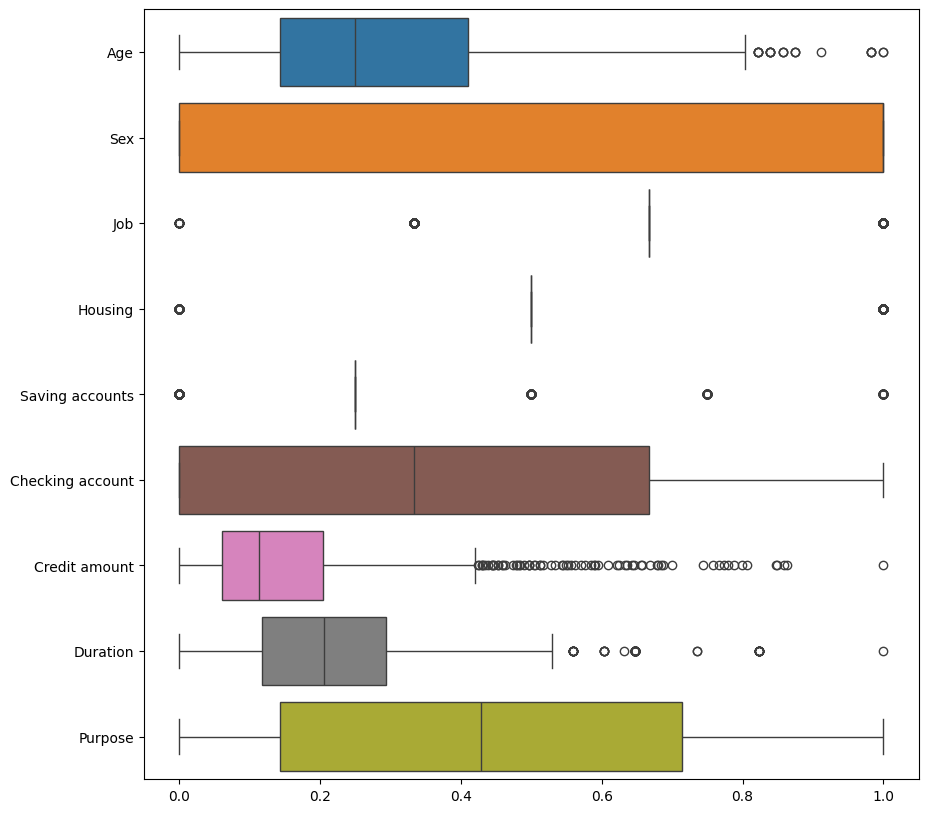

In [764]:
plt.figure(figsize=(10,10))
sns.boxplot(data=data_scaled, orient='h')

Приведение данных к общему масштабу необходимо для схождения модели в процессе обучения, а также чтобы признаки с большими значениями в диапазоне не расценивались моделью как более значимые.

## Часть 2. Моделирование.

Постройте три варианта кластеризации: k-means, hierarhical и DBSCAN, подберите оптимальное количество кластеров для каждого метода при помощи Elbow method и Silhouette plot;
Также воспользуйтесь различными вариантами сжатия признакового пространства (PCA, UMAP, tSNE) и визуализируйте результаты кластеризации на двумерной плоскости.

## PCA

(1000, 2)

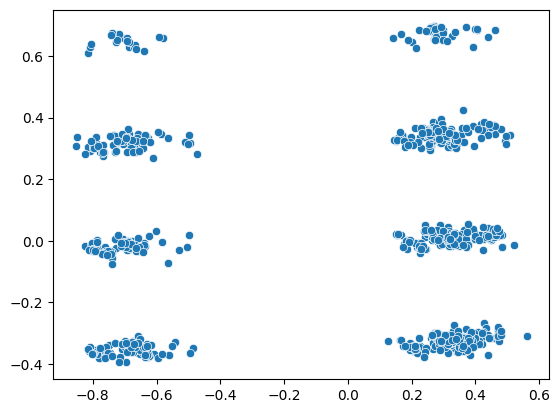

In [765]:
from sklearn.decomposition import PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)
sns.scatterplot(x=X_pca[:,0], y=X_pca[:,1])
X_pca.shape


## UMAP

(1000, 2)

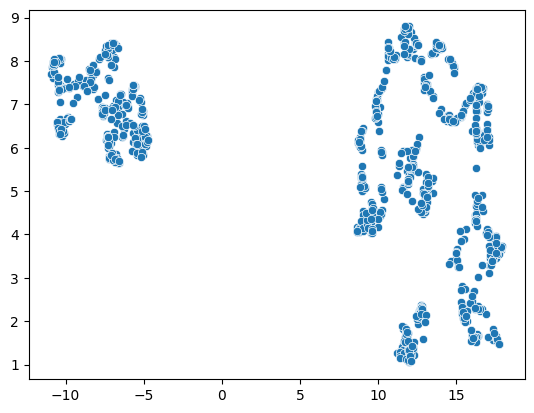

In [766]:
from umap import UMAP
umap = UMAP()
X_umap = umap.fit_transform(X)
sns.scatterplot(x=X_umap[:,0], y=X_umap[:,1])
X_umap.shape

## tSNE

(1000, 2)

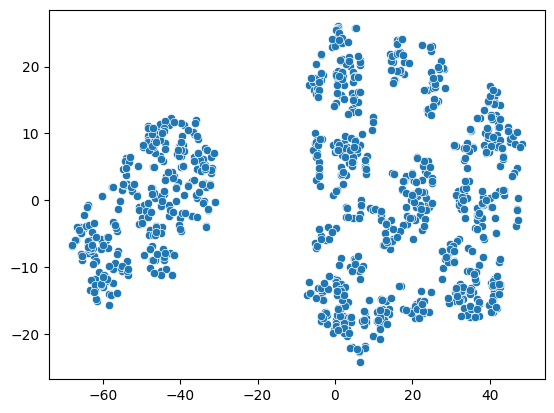

In [767]:
#data_scaled = data_scaled[data_scaled.columns.drop('Sex')]

from sklearn.manifold import TSNE
tsne = TSNE(n_components=2, random_state=10)
X_tsne = tsne.fit_transform(X)
sns.scatterplot(x=X_tsne[:,0], y=X_tsne[:,1])
X_tsne.shape


## K-Means

In [768]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from tqdm import tqdm

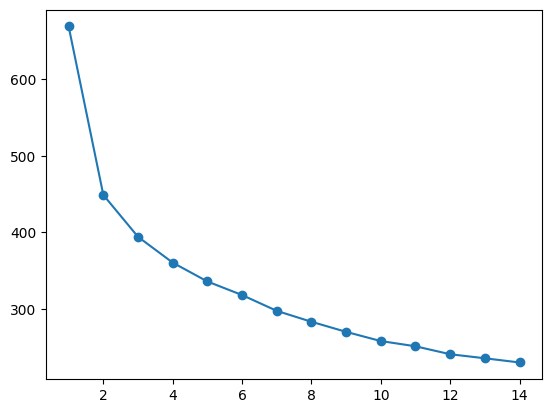

In [769]:
inertia = []
for i in range(1,15):
    kmeans = KMeans(n_clusters=i, random_state=10, n_init=10).fit(X)
    labels = kmeans.labels_
    inertia_i = kmeans.inertia_
    inertia.append(inertia_i)

plt.plot(range(1,15), inertia, marker='o')

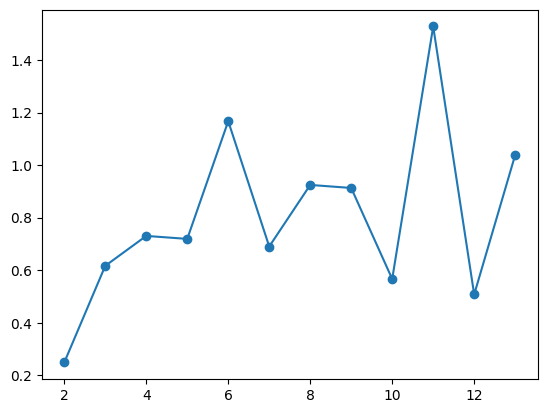

In [770]:
D = []
for i in range(1,13):
    Di = (inertia[i] - inertia[i+1])/(inertia[i-1] - inertia[i])
    D.append(Di)

plt.plot(range(2,14), D, marker='o')

Локоть не выражен, используем метод силуэта

In [771]:
def kmeans_clustering(cluster_range, X):
    silhouette = []
    for i in tqdm(cluster_range):
        kmeans = KMeans(n_clusters=i, random_state=10, n_init=10).fit(X)
        labels = kmeans.labels_
        score = silhouette_score(X, labels)
        silhouette.append(score)
    plt.plot(range(2,14), silhouette, marker='o')

100%|██████████| 12/12 [00:01<00:00,  8.01it/s]


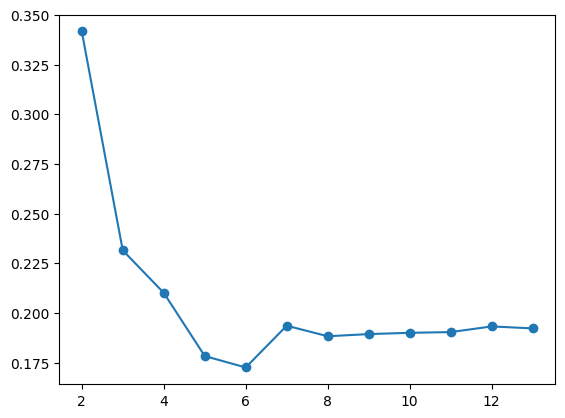

In [772]:
cluster_range = range(2,14)
kmeans_clustering(cluster_range,X)

In [773]:
kmeans = KMeans(n_clusters=2, random_state=10, n_init=10).fit(X)
labels = kmeans.labels_

<Axes: >

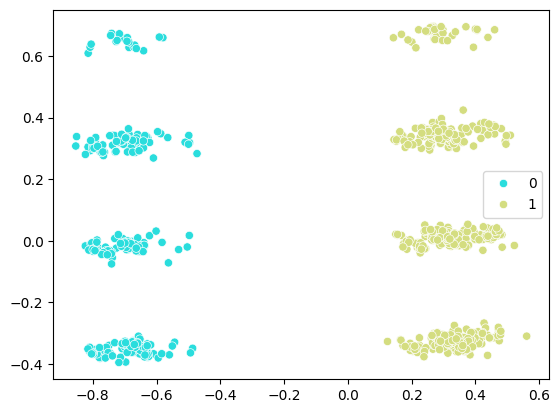

In [774]:
sns.scatterplot(x=X_pca[:,0], y=X_pca[:,1], hue=labels, palette='rainbow')

<Axes: >

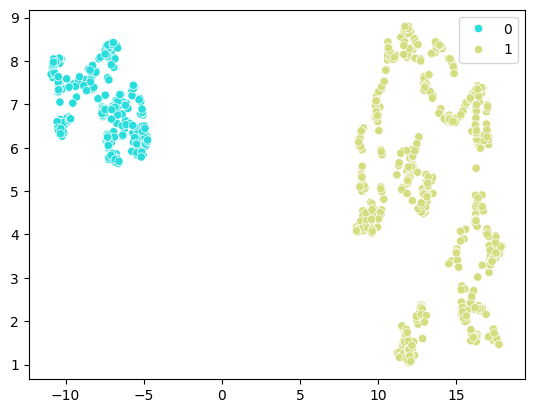

In [775]:
sns.scatterplot(x=X_umap[:,0], y=X_umap[:,1], hue=labels, palette='rainbow')

<Axes: >

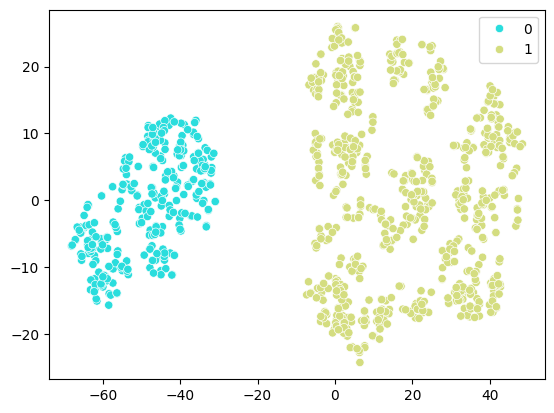

In [776]:
sns.scatterplot(x=X_tsne[:,0], y=X_tsne[:,1], hue=labels, palette='rainbow')

In [777]:
df['labels_kmeans'] = labels
data_scaled['labels_kmeans'] = labels

## Hierarhical

In [778]:
from sklearn.cluster import AgglomerativeClustering, DBSCAN
from scipy.cluster.hierarchy import dendrogram, linkage

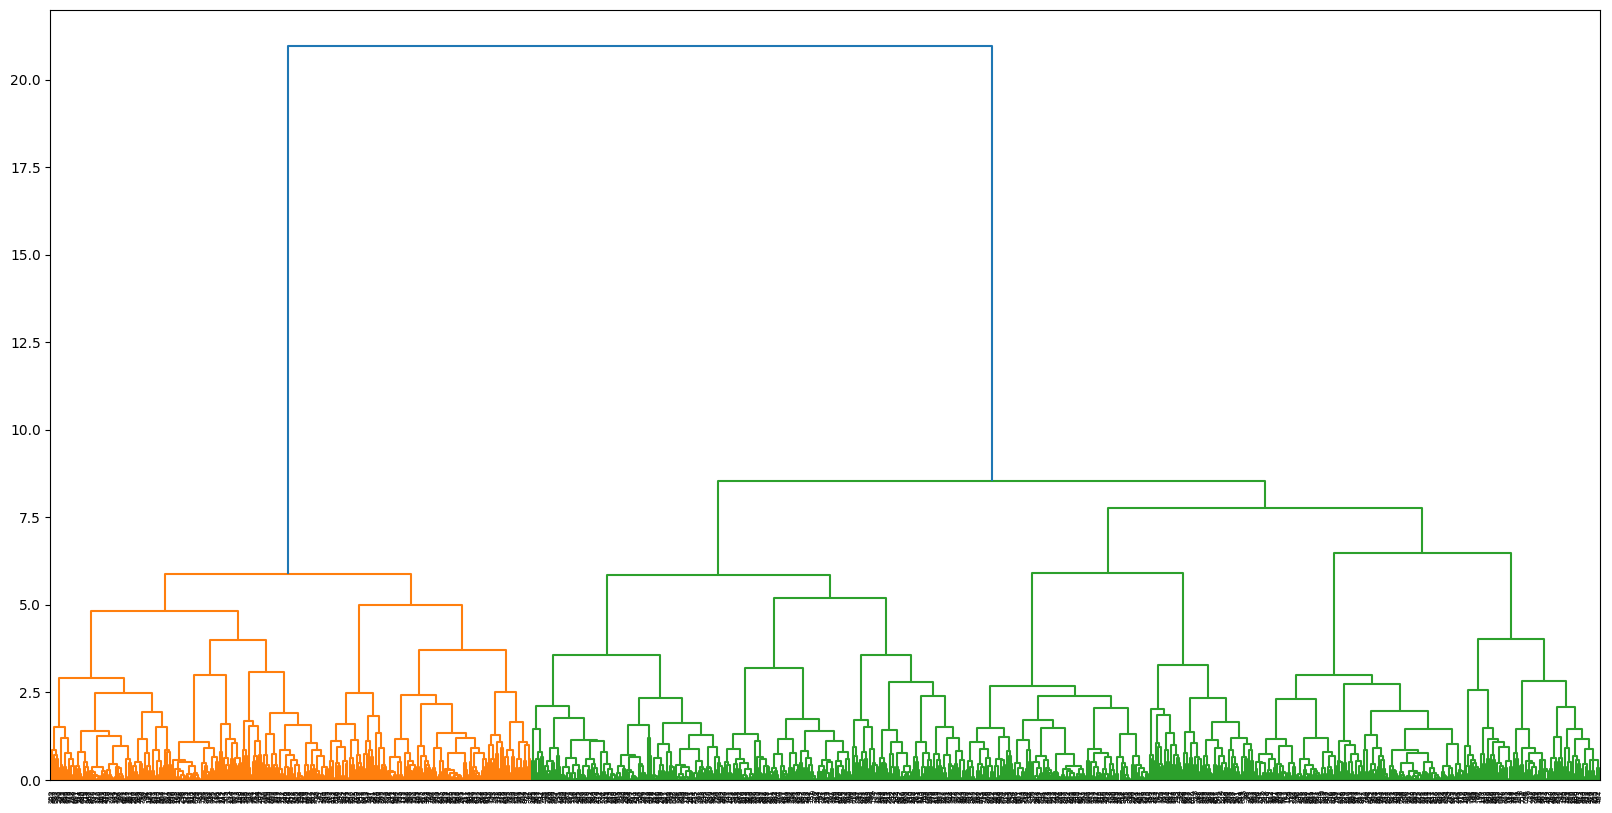

In [779]:
plt.figure(figsize=(20,10))
linkage_ = linkage(X, method='ward')
dendrogram_ = dendrogram(linkage_)

In [780]:
def agglomerative_clustering(cluster_range, X):
    silhouette = []
    for i in tqdm(cluster_range):
        agg = AgglomerativeClustering(n_clusters=i).fit(X)
        labels = agg.labels_
        score = silhouette_score(X, labels)
        silhouette.append(score)
    plt.plot(range(2,14), silhouette, marker='o')

  0%|          | 0/12 [00:00<?, ?it/s]

100%|██████████| 12/12 [00:00<00:00, 26.79it/s]


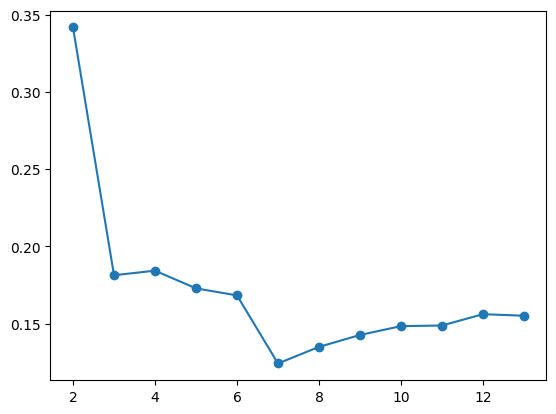

In [781]:
cluster_range = range(2,14)
agglomerative_clustering(cluster_range,X)

In [782]:
agg = AgglomerativeClustering(n_clusters=2).fit(X)
labels = agg.labels_

<Axes: >

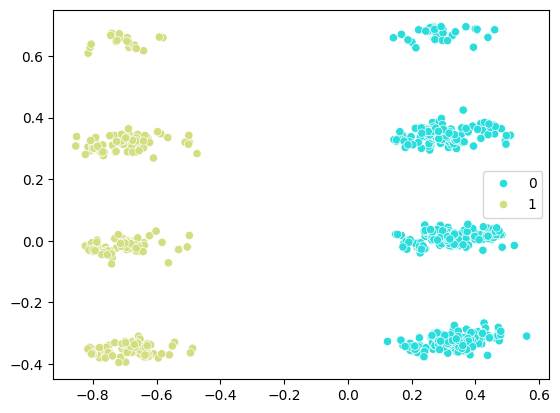

In [783]:
sns.scatterplot(x=X_pca[:,0], y=X_pca[:,1], hue=labels, palette='rainbow')

<Axes: >

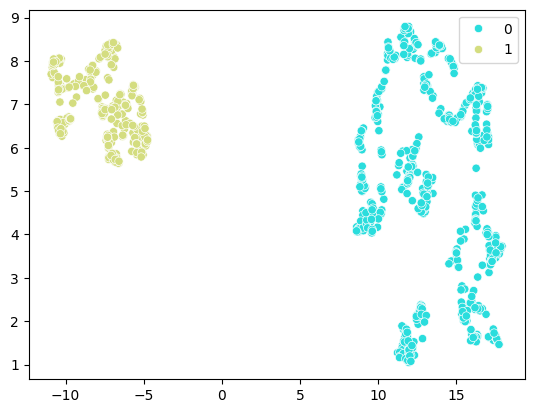

In [784]:
sns.scatterplot(x=X_umap[:,0], y=X_umap[:,1], hue=labels, palette='rainbow')

<Axes: >

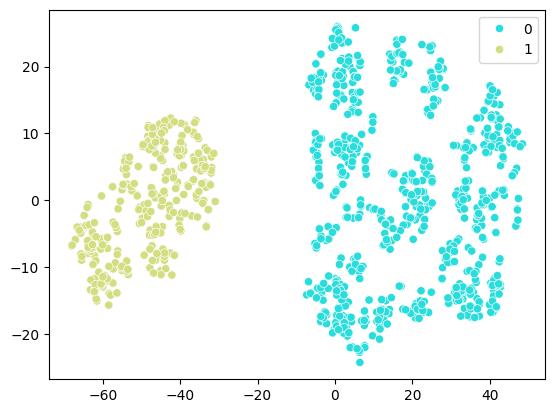

In [785]:
sns.scatterplot(x=X_tsne[:,0], y=X_tsne[:,1], hue=labels, palette='rainbow')

In [786]:
df['labels_agg'] = labels
data_scaled['labels_agg'] = labels

# DBSCAN

In [787]:
def dbscan_clustering(eps_range, X):
    eps_range = eps_range
    silhouette = []
    clusters = []
    for i in tqdm(eps_range):
        dbscan = DBSCAN(eps=i).fit(X)
        labels = dbscan.labels_
        uniq_labels = np.unique(labels)
        n_clusters = len(uniq_labels[uniq_labels != -1])
        if n_clusters > 1:
            score = silhouette_score(X, labels)
        else:
            score = 0
        silhouette.append(score)
        clusters.append(n_clusters)
        
    fig, ax1 = plt.subplots()

    color = 'tab:red'
    ax1.plot(eps_range, silhouette, marker='o', color=color)
    ax1.set_xlabel('eps')
    ax1.set_ylabel('silhouette', color=color)
    ax1.tick_params(axis='y', labelcolor=color)

    ax2 = ax1.twinx()  # instantiate a second axes that shares the same x-axis

    color = 'tab:blue'
    ax2.plot(eps_range, clusters, marker='o', color=color)
    ax2.set_ylabel('n_clusters', color=color)  
    ax2.tick_params(axis='y', labelcolor=color)

    fig.tight_layout()  # otherwise the right y-label is slightly clipped
    plt.show()

100%|██████████| 19/19 [00:00<00:00, 20.34it/s]


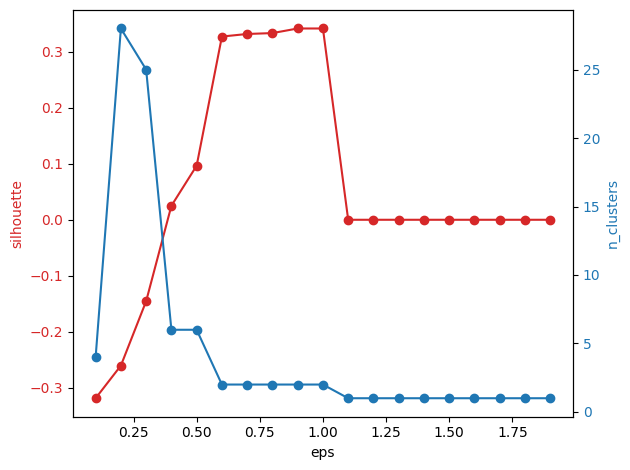

In [788]:
eps_range = np.arange(0.1,2,0.1)
dbscan_clustering(eps_range, X)

In [789]:
dbscan = DBSCAN(eps=1.0).fit(X)
labels = dbscan.labels_

<Axes: >

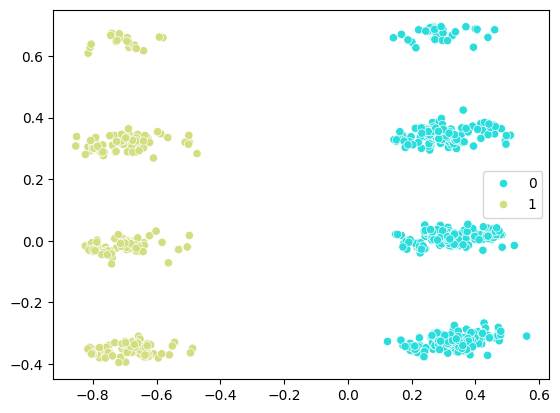

In [790]:
sns.scatterplot(x=X_pca[:,0], y=X_pca[:,1], hue=labels, palette='rainbow')

<Axes: >

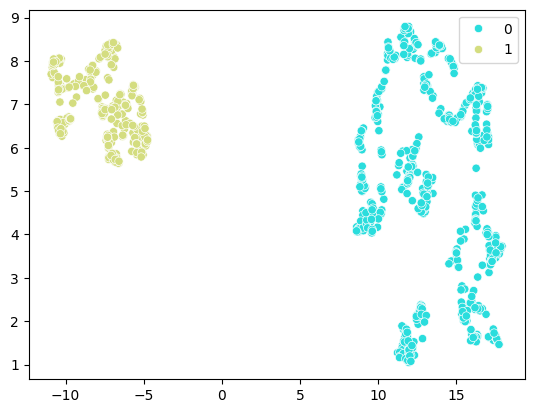

In [791]:
sns.scatterplot(x=X_umap[:,0], y=X_umap[:,1], hue=labels, palette='rainbow')

<Axes: >

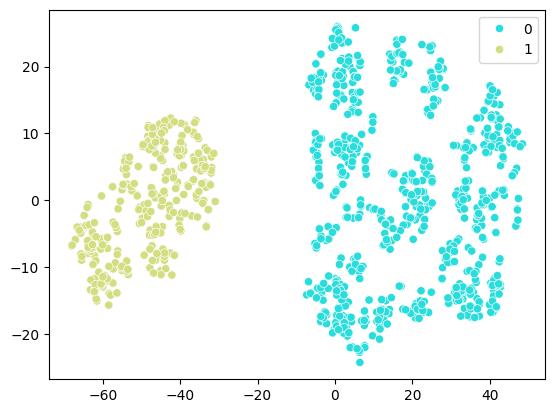

In [792]:
sns.scatterplot(x=X_tsne[:,0], y=X_tsne[:,1], hue=labels, palette='rainbow')

In [793]:
df['labels_dbscan'] = labels
data_scaled['labels_dbscan'] = labels

## Часть 3. Интерпретация.

Теперь ваша задача - попытаться проинтерпретировать получившиеся кластеры, начните с простого расчета средних значений признаков для каждого из кластеров, есть ли интересные закономерности?

Теперь постройте boxplot-ы для каждого признака, сгруппировав значения по кластерам, по каким признакам заметно наибольшее отличие кластеров друг от друга? Можно ли их интерпретировать?

In [794]:
#import dtale
#dtale.show(df)

df

,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose,labels_kmeans,labels_agg,labels_dbscan
0,67,male,2,own,Missing,little,1169,6,radio/TV,1,0,0
1,22,female,2,own,little,moderate,5951,48,radio/TV,0,1,1
2,49,male,1,own,little,Missing,2096,12,education,1,0,0
3,45,male,2,free,little,little,7882,42,furniture/equipment,1,0,0
4,53,male,2,free,little,little,4870,24,car,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...
995,31,female,1,own,little,Missing,1736,12,furniture/equipment,0,1,1
996,40,male,3,own,little,little,3857,30,car,1,0,0
997,38,male,2,own,little,Missing,804,12,radio/TV,1,0,0
998,23,male,2,free,little,little,1845,45,radio/TV,1,0,0


In [795]:
data_scaled['labels_kmeans'].value_counts(normalize=True).sort_index()

labels_kmeans
0    0.31
1    0.69
Name: proportion, dtype: float64

In [796]:
data_scaled.groupby('labels_kmeans').median().T.round(2)

labels_kmeans,0,1
Age,0.18,0.29
Sex,0.00,1.00
Job,0.67,0.67
Housing,0.50,0.50
Saving accounts,0.25,0.25
Checking account,0.33,0.33
Credit amount,0.09,0.12
Duration,0.21,0.21
Purpose,0.57,0.43
labels_agg,1.00,0.00


In [797]:
data_scaled['labels_agg'].value_counts(normalize=True).sort_index()

labels_agg
0    0.69
1    0.31
Name: proportion, dtype: float64

In [798]:
data_scaled.groupby('labels_agg').median().T.round(2)

labels_agg,0,1
Age,0.29,0.18
Sex,1.00,0.00
Job,0.67,0.67
Housing,0.50,0.50
Saving accounts,0.25,0.25
Checking account,0.33,0.33
Credit amount,0.12,0.09
Duration,0.21,0.21
Purpose,0.43,0.57
labels_kmeans,1.00,0.00


In [799]:
data_scaled['labels_dbscan'].value_counts(normalize=True).sort_index()

labels_dbscan
0    0.69
1    0.31
Name: proportion, dtype: float64

In [800]:
data_scaled.groupby('labels_dbscan').median().T.round(2)

labels_dbscan,0,1
Age,0.29,0.18
Sex,1.00,0.00
Job,0.67,0.67
Housing,0.50,0.50
Saving accounts,0.25,0.25
Checking account,0.33,0.33
Credit amount,0.12,0.09
Duration,0.21,0.21
Purpose,0.43,0.57
labels_kmeans,1.00,0.00


Алгоритм кластеризации k-means, иерархическая кластеризация и алгоритм DBSCAN выделяют 2 кластера, которые соответствуют полу клиента.

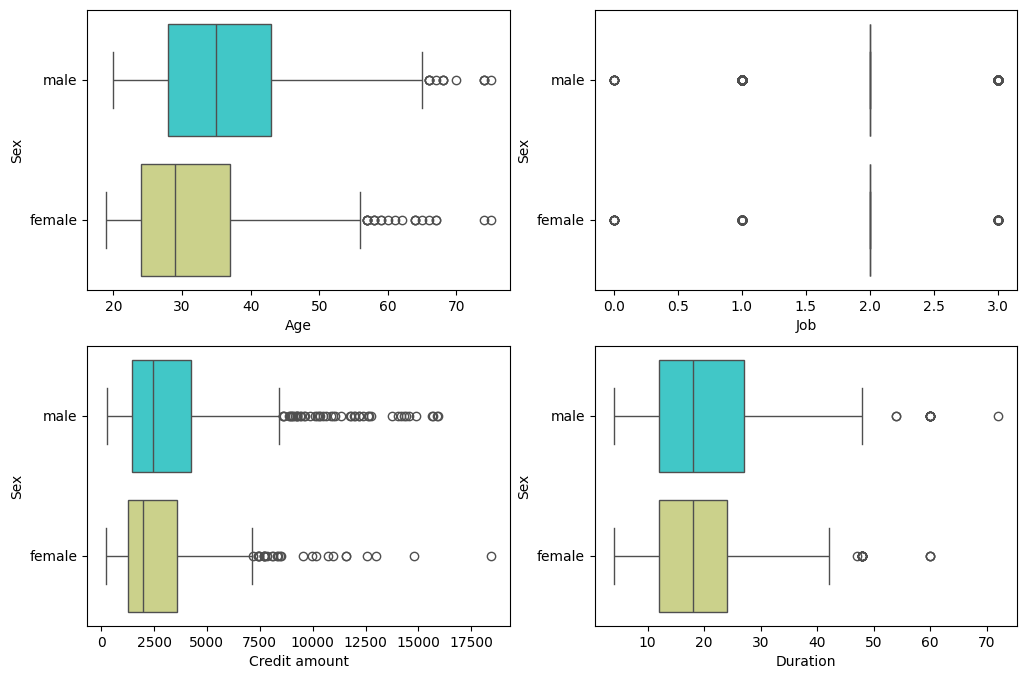

In [801]:
ncols = 2
nrows = math.ceil(len(df_num.columns)/ncols)

figure, axis = plt.subplots( nrows, ncols,figsize=(12, 8))
for i, col in enumerate(df_num):
   sns.boxplot(ax=axis[i//ncols, i%ncols],x=df[col],y=df['Sex'], palette='rainbow')

In [804]:
#Добавим столбец со словесным описанием работы (Job (numeric: 0 - unskilled and non-resident, 1 - unskilled and resident, 2 - skilled, 3 - highly skilled))
dic = {0: 'unskilled and non-resident', 1: 'unskilled and resident', 2: 'skilled', 3: 'highly skilled'}
df['Job_txt'] = df['Job'].replace(dic)
df_cat['Job_txt'] = df['Job_txt']

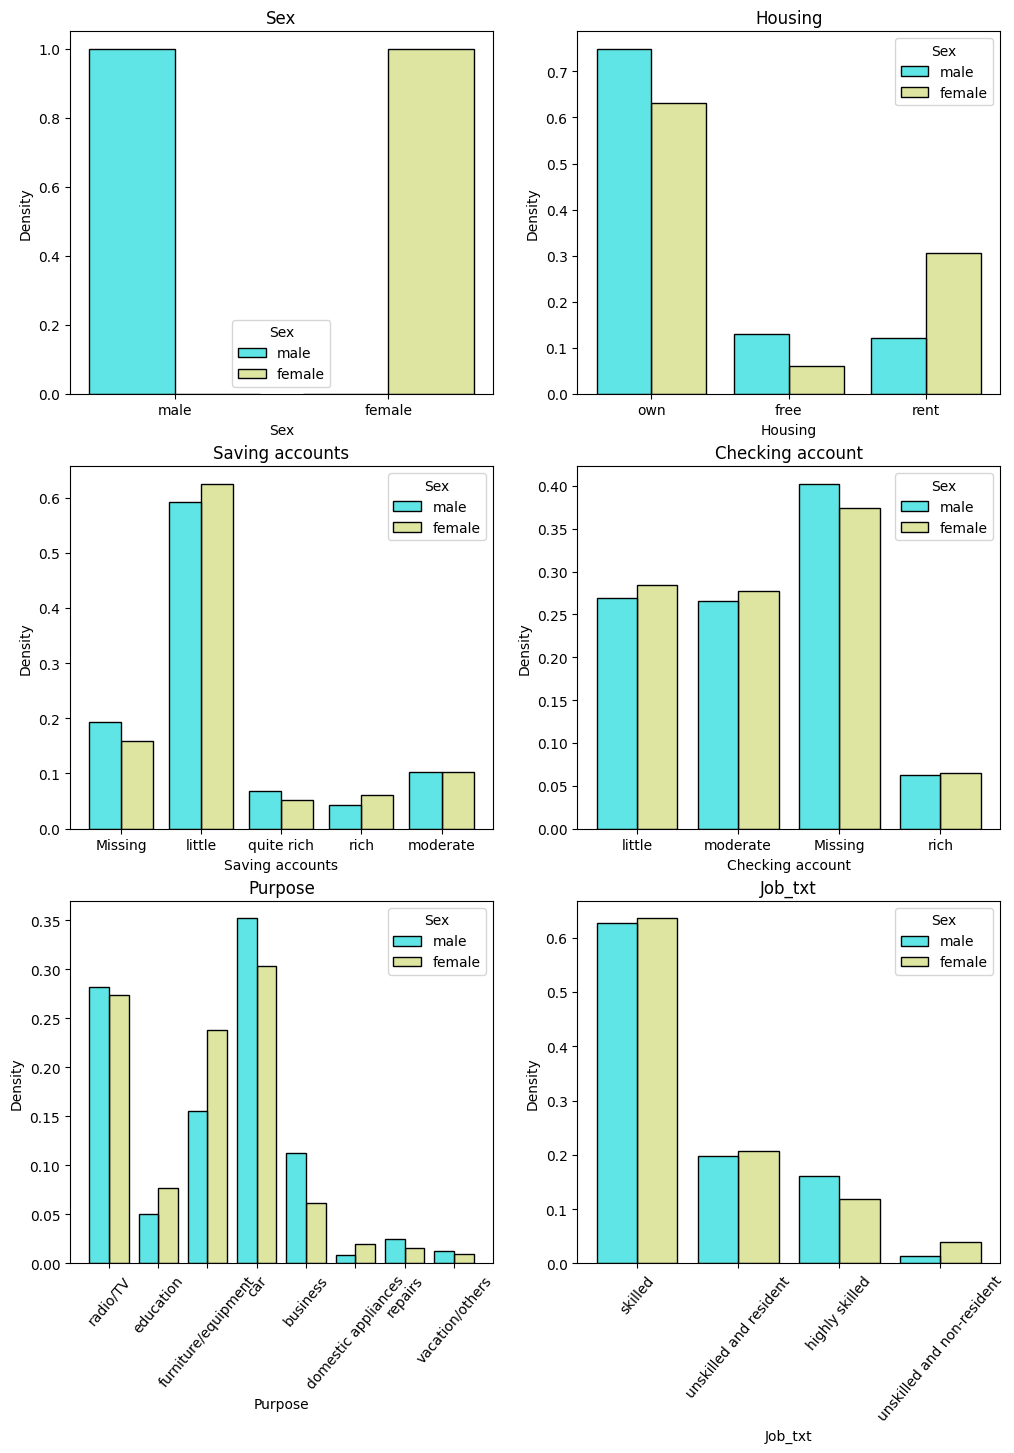

In [803]:
ncols = 2
nrows = math.ceil(len(df_cat.columns)/ncols)
figure, axis = plt.subplots( nrows, ncols,figsize=(12, 16))

for i, col in enumerate(df_cat):
   sns.histplot(ax=axis[i//ncols, i%ncols], data=df,  x = col, hue="Sex",palette='rainbow', stat='density', multiple="dodge", shrink=.8, common_norm = False)
   axis[i//ncols, i%ncols].set_title(col)

axis[2,0].tick_params(axis='x', labelrotation=50)
axis[2,1].tick_params(axis='x', labelrotation=50)

Основные отличия между кластерами:
1. Клиенты мужчины в среднем старше по возрасту
2. Больше сумма кредита у мужчин
3. Различаются цели взятия кредита: для мужчин - бизнес, ремонт и автомобиль, для женщин - мебель, бытовая техника, образование
4. Женщины чаще снимают жилье. Мужчины чаще проживают в собственном жилье или используют бесплатное жилье
5. Среди женщин больше приезжих занимающихся неквалифицированным трудом